# ALM integrado: generación de activos + optimización de portafolio

Este notebook **une en un solo lugar** lo que antes estaba repartido en dos notebooks:

1. `activos_modelados.ipynb` → genera las trayectorias de retornos de los activos (Bono,
   Fondo, ETF) mediante brownianos, y estima `mu` (retornos esperados) y `Sigma`
   (covarianzas).
2. `optimizacion_portafolio_ALM.ipynb` → usa `mu`, `Sigma` y las trayectorias para
   resolver el Markowitz multiperiodo y analizar el *shortfall*.

## ¿Por qué un solo notebook?

La ventaja es que **todo pasa en memoria**: no se escriben ni se leen archivos
intermedios (`mu_activos.csv`, `Sigma_mensual.csv`, `trayectorias_mensuales.npz`...).
Así puedes cambiar en la **sección 1**:

- las **rentabilidades** (`ranges`),
- la **cantidad de trayectorias** (`K`),
- **cómo modelas los brownianos** (`wiener_process`, `sample_active_trajectory`, `vols`),

y volver a ejecutar de arriba a abajo para ver cómo cambian el portafolio óptimo, el
capital residual y el riesgo de shortfall, sin tocar ningún archivo.

Si quieres, al final hay una celda opcional para **exportar** los resultados a disco (los
mismos CSV/NPZ que generaban los notebooks originales), pero por defecto está desactivada.

## 0. Librerías y optimizador

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Optimizador: cvxpy si está disponible; si no, scipy.optimize (SLSQP)
try:
    import cvxpy as cp
    USAR_CVXPY = True
except ImportError:
    USAR_CVXPY = False

from scipy.optimize import minimize

print('Optimizador:', 'cvxpy' if USAR_CVXPY else 'scipy.optimize (fallback)')

Optimizador: scipy.optimize (fallback)


## 1. PARÁMETROS — edita aquí todo

Esta es la **única celda que necesitas tocar** para experimentar. Agrupa:

### 1.a Generación de activos (lo que antes estaba en `activos_modelados.ipynb`)
- `SEED`: semilla para reproducibilidad.
- `K`: **número de trayectorias** Monte Carlo (sube/baja según la potencia de tu máquina).
- `years`, `days_per_year`: horizonte diario de simulación.
- `ranges`: **rentabilidades** anuales (mín, máx) de cada activo.
- `vols`: volatilidades relativas que controlan cuánto oscila cada browniano.

### 1.b Portafolio ALM (lo que antes estaba en `optimizacion_portafolio_ALM.ipynb`)
- `C0`: capital inicial.
- `SIGMA_MAX_ANUAL`: tope de riesgo anual.
- `BETA_LIQUIDEZ`: liquidez mínima `w_Fondo + w_ETF`.
- `CARPETA_FLUJOS`, `ARCHIVO_FLUJO`: serie del pasivo `L_t` (intercambiable: mbg/arima/sarimax).

In [24]:
# ============================================================
# 1.a  GENERACIÓN DE ACTIVOS (brownianos, rentabilidades, K)
# ============================================================
SEED = 42                 # reproducibilidad

years = 10
days_per_year = 365
N = years * days_per_year        # 3650 días

K = 1000                        # <-- CANTIDAD DE TRAYECTORIAS (ajústala a tu máquina)

assets = ['Bono', 'Fondo', 'ETF']

# <-- RENTABILIDADES anuales (mínimo, máximo) de cada activo
ranges = {
    'Bono':  (0.07, 0.10),
    'Fondo': (0.04, 0.06),
    'ETF':   (0.08, 0.15),
}

# <-- Volatilidades relativas (controlan cómo modelas los brownianos)
vols = {
    'Bono':  1/40,
    'Fondo': 1/100,
    'ETF':   1/200,
}

days_per_month = 30
N_MONTHS_EXPORT = 120            # horizonte objetivo para el ALM (10 años)

# ============================================================
# 1.b  PORTAFOLIO ALM
# ============================================================
C0 = 760_000_000.0               # capital inicial (COP)
SIGMA_MAX_ANUAL = 0.08           # riesgo máximo anual (8%)
BETA_LIQUIDEZ = 0.30             # w_Fondo + w_ETF >= 0.30

# Pesos mínimos por activo (fracción del portafolio). 0.0 = sin mínimo.
# Solo se aplica a los activos que están permitidos en ese periodo.
PESOS_MIN = {
    'Bono':  0.00,   # ejemplo: al menos 10% en Bono cuando esté disponible
    'Fondo': 0.00,
    'ETF':   0.00,   # ejemplo: al menos 5% en ETF
}

# Opcional pero recomendable: pesos máximos (1.0 = sin máximo efectivo)
PESOS_MAX = {
    'Bono':  1.0,
    'Fondo': 1.0,
    'ETF':   1.0,
}

# Conversión coherente de riesgo anual -> mensual (varianza escala lineal con el tiempo)
SIGMA_MAX_MENSUAL = SIGMA_MAX_ANUAL / np.sqrt(12)

# Serie del pasivo (intercambiable):
#   'flujo_pronostico_uvr_mbg.csv', 'flujo_pronostico_uvr_arima.csv', 'flujo_pronostico_uvr_Sarimax.csv'
CARPETA_FLUJOS = '../flujosPronosticados'
ARCHIVO_FLUJO = 'flujo_pronostico_uvr_mbg.csv'

# Reproducibilidad global
np.random.seed(SEED)

print(f'K (trayectorias)        : {K}')
print(f'Horizonte               : {years} años = {N} días ({N // days_per_month} meses aprox.)')
print(f'Capital inicial C0      : {C0:,.0f} COP')
print(f'Sigma max anual         : {SIGMA_MAX_ANUAL:.2%}  ->  mensual {SIGMA_MAX_MENSUAL:.4%}')
print(f'Liquidez minima (beta)  : {BETA_LIQUIDEZ:.0%}')
print(f'Pesos mínimos              : {PESOS_MIN}')
print(f'Pesos máximos              : {PESOS_MAX}')
print(f'Flujo del pasivo        : {ARCHIVO_FLUJO}')

K (trayectorias)        : 1000
Horizonte               : 10 años = 3650 días (121 meses aprox.)
Capital inicial C0      : 760,000,000 COP
Sigma max anual         : 8.00%  ->  mensual 2.3094%
Liquidez minima (beta)  : 30%
Pesos mínimos              : {'Bono': 0.0, 'Fondo': 0.0, 'ETF': 0.0}
Pesos máximos              : {'Bono': 1.0, 'Fondo': 1.0, 'ETF': 1.0}
Flujo del pasivo        : flujo_pronostico_uvr_mbg.csv


## 2. Funciones de generación de brownianos

Mismas funciones que `activos_modelados.ipynb`. **Aquí es donde modelas los brownianos**:
si quieres cambiar la forma del proceso (p. ej. otra escala de la volatilidad, otro
clipping, o un proceso distinto), edita `wiener_process` y `sample_active_trajectory`.

In [25]:
def year_to_daily(rate):
    """Convierte tasa efectiva anual a tasa diaria equivalente."""
    return (1 + rate) ** (1 / 365) - 1


def wiener_process(N, time_step=1 / 365):
    """Genera un proceso de Wiener (Browniano) de longitud N."""
    increments = np.sqrt(time_step) * np.random.randn(N - 1)
    W = np.concatenate([[0], np.cumsum(increments)])
    return W


def sample_active_trajectory(min_annual, max_annual, volatility, N):
    """Genera UNA trayectoria diaria de retorno acotada entre min y max.

    Devuelve un array de longitud N con retornos diarios.
    """
    min_d = year_to_daily(min_annual)
    max_d = year_to_daily(max_annual)
    mu = (min_d + max_d) / 2
    half = (max_d - min_d) / 2
    sig = np.sqrt(half / 5) * volatility   # misma lógica del notebook original

    W = wiener_process(N)
    x = mu + sig * W

    # Acotar al rango [min_d, max_d]
    x = np.clip(x, min_d, max_d)
    return x

## 3. Generación de trayectorias diarias

Para cada activo generamos `K` trayectorias de `N` días. El resultado queda en el dict
`trajectories` (forma `(K, N)` por activo).

In [26]:
trajectories = {asset: np.zeros((K, N)) for asset in assets}

for asset in assets:
    min_r, max_r = ranges[asset]
    vol = vols[asset]
    for k in range(K):
        trajectories[asset][k, :] = sample_active_trajectory(min_r, max_r, vol, N)

print(f'Generadas {K} trayectorias de {N} días para cada activo.')

Generadas 1000 trayectorias de 3650 días para cada activo.


## 4. Retornos mensuales

Convertimos los retornos diarios a **retornos mensuales** (ventanas de 30 días,
compuestos: `prod(1 + r) - 1`). Estos son los que usamos para `mu`, `Sigma` y el ALM.

In [27]:
n_months = N // days_per_month   # ~121 meses

monthly_returns = {asset: np.zeros((K, n_months)) for asset in assets}

for asset in assets:
    daily_all = trajectories[asset]
    for m in range(n_months):
        start = m * days_per_month
        end = start + days_per_month
        window = daily_all[:, start:end]             # (K, 30)
        monthly_returns[asset][:, m] = np.prod(1 + window, axis=1) - 1

print(f'Retornos mensuales shape: {monthly_returns["Bono"].shape}  (K x meses)')

Retornos mensuales shape: (1000, 121)  (K x meses)


## 5. Estimación de `mu` y `Sigma`

Apilamos todas las observaciones mensuales (K × n_months) y estimamos el vector de
retornos esperados `mu_mensual` y la matriz de covarianzas `Sigma_df` (mensuales).
Estos objetos quedan **en memoria** y los consume directamente el ALM (sin pasar por CSV).

In [28]:
all_monthly = np.column_stack([monthly_returns[a].ravel() for a in assets])

mu_vec = all_monthly.mean(axis=0)
Sigma_mat = np.cov(all_monthly, rowvar=False)

# Objetos que usará el ALM (mismos nombres que el notebook de optimización)
ACTIVOS = list(assets)
mu_mensual = pd.Series(mu_vec, index=ACTIVOS, name='mu_mensual')
Sigma_df = pd.DataFrame(Sigma_mat, index=ACTIVOS, columns=ACTIVOS)

mu_annual = (1 + mu_vec) ** 12 - 1
Sigma_annual = Sigma_mat * 12

mu_df = pd.DataFrame({'mu_mensual': mu_vec, 'mu_anual': mu_annual}, index=ACTIVOS)
mu_df.index.name = 'Activo'

print('mu mensual (Bono, Fondo, ETF):')
print(mu_mensual.to_string())
print('\nmu anualizado aproximado:')
print(pd.Series(mu_annual, index=ACTIVOS).to_string())
print('\nSigma mensual:')
display(Sigma_df)

mu mensual (Bono, Fondo, ETF):
Bono     0.006700
Fondo    0.004013
ETF      0.008931

mu anualizado aproximado:
Bono     0.083432
Fondo    0.049236
ETF      0.112592

Sigma mensual:


,Bono,Fondo,ETF
Bono,1.065227e-06,-1.214040e-08,-1.197051e-08
Fondo,-1.214040e-08,4.122838e-07,7.250066e-09
ETF,-1.197051e-08,7.250066e-09,1.617392e-06


## 6. Trayectorias mensuales en memoria (alineadas a 120 meses)

Alineamos las trayectorias mensuales al horizonte del ALM (`N_MONTHS_EXPORT = 120`).
El dict `R_tray` (forma `(K, 120)` por activo) es el que usará el análisis de shortfall,
sin necesidad de leer `trayectorias_mensuales.npz` ni los CSV.

In [29]:
def alinear_120(mat, objetivo=N_MONTHS_EXPORT):
    """Devuelve una copia de 'mat' (K, n_months) alineada a 'objetivo' columnas."""
    K_, M_ = mat.shape
    if M_ >= objetivo:
        return mat[:, :objetivo].copy()
    pad = np.zeros((K_, objetivo - M_))
    return np.hstack([mat, pad])


R_tray = {asset: alinear_120(monthly_returns[asset]) for asset in assets}
K_SIM = K
N_SIM = N_MONTHS_EXPORT
ACTIVOS_TRAY = list(assets)

if n_months > N_MONTHS_EXPORT:
    print(f'[info] n_months={n_months} > {N_MONTHS_EXPORT}: se recortan los primeros {N_MONTHS_EXPORT} meses.')
elif n_months < N_MONTHS_EXPORT:
    print(f'[aviso] n_months={n_months} < {N_MONTHS_EXPORT}: se rellenan con 0.0.')
else:
    print(f'[info] n_months={n_months} == {N_MONTHS_EXPORT}: sin recorte ni relleno.')

print('\nControl: media de las trayectorias vs mu_mensual esperado')
for a in ACTIVOS_TRAY:
    print(f'  {a:<6}: media_sim = {R_tray[a].mean():.5f}   mu_mensual = {mu_mensual[a]:.5f}')

[info] n_months=121 > 120: se recortan los primeros 120 meses.

Control: media de las trayectorias vs mu_mensual esperado
  Bono  : media_sim = 0.00670   mu_mensual = 0.00670
  Fondo : media_sim = 0.00401   mu_mensual = 0.00401
  ETF   : media_sim = 0.00893   mu_mensual = 0.00893


## 7. Carga del pasivo `L_t`

Lo único que se lee de disco es la serie del pasivo (el crédito a cubrir), porque no se
genera aquí. `mu`, `Sigma` y las trayectorias ya están en memoria de las secciones previas.

In [30]:
flujo_df = pd.read_csv(os.path.join(CARPETA_FLUJOS, ARCHIVO_FLUJO))
flujo_df = flujo_df.sort_values('periodo').reset_index(drop=True)
Lt = flujo_df['Lt'].to_numpy()
N_MESES = len(Lt)

print(f'Meses del pasivo: {N_MESES} | Total a pagar: {Lt.sum():,.0f} COP | '
      f'Primer pago en mes {int(flujo_df.loc[flujo_df.Lt > 0, "periodo"].min())}')

Meses del pasivo: 120 | Total a pagar: 986,738,889 COP | Primer pago en mes 37


## 8. Periodos del ALM y optimizador de Markowitz

El Bono solo se puede renovar cada 36 meses (vence a 3 años); en el último tramo
(meses 109–120) solo quedan Fondo y ETF.

In [31]:
# (nombre, mes_inicio, mes_fin, activos_permitidos)  -- meses base 1, inclusivos
PERIODOS = [
    ('P1', 1,   36,  ['Bono', 'Fondo', 'ETF']),
    ('P2', 37,  72,  ['Bono', 'Fondo', 'ETF']),
    ('P3', 73,  108, ['Bono', 'Fondo', 'ETF']),
    ('P4', 109, 120, ['Fondo', 'ETF']),          # sin Bono
]

for nombre, ini, fin, act in PERIODOS:
    print(f'{nombre}: meses {ini:>3}-{fin:<3} | activos: {act}')

P1: meses   1-36  | activos: ['Bono', 'Fondo', 'ETF']
P2: meses  37-72  | activos: ['Bono', 'Fondo', 'ETF']
P3: meses  73-108 | activos: ['Bono', 'Fondo', 'ETF']
P4: meses 109-120 | activos: ['Fondo', 'ETF']


In [32]:
def optimizar_periodo(activos_permitidos, mu_mensual, Sigma_df,
                      sigma_max_mensual, beta_liquidez,
                      pesos_min=None, pesos_max=None):
    """Resuelve el Markowitz de un periodo y devuelve los pesos óptimos.

    max_w  w'mu
    s.a.   w'Sigma w <= sigma_max^2
           sum w = 1
           pesos_min[a] <= w_a <= pesos_max[a]   (solo para activos permitidos)
           w_Fondo + w_ETF >= beta
    Devuelve {activo: peso} para TODOS los activos (0 si no participa).
    """
    mu = mu_mensual.loc[activos_permitidos].to_numpy()
    Sigma = Sigma_df.loc[activos_permitidos, activos_permitidos].to_numpy()
    n = len(activos_permitidos)
    idx_liquidos = [i for i, a in enumerate(activos_permitidos) if a in ('Fondo', 'ETF')]

    if pesos_min is None:
        pesos_min = {a: 0.0 for a in activos_permitidos}
    if pesos_max is None:
        pesos_max = {a: 1.0 for a in activos_permitidos}

    # Vectores alineados con activos_permitidos
    w_lb = np.array([float(pesos_min.get(a, 0.0)) for a in activos_permitidos])
    w_ub = np.array([float(pesos_max.get(a, 1.0)) for a in activos_permitidos])

    # Validación: los mínimos de los activos permitidos no pueden superar 1
    if w_lb.sum() > 1.0 + 1e-9:
        raise ValueError(f'Pesos mínimos incompatibles en {activos_permitidos}: '
                         f'suma={w_lb.sum():.3f} > 1')

    if USAR_CVXPY:
        w = cp.Variable(n)
        objetivo = cp.Maximize(mu @ w)
        restricciones = [
            cp.sum(w) == 1,
            w >= w_lb,                                          # <-- pesos mínimos
            w <= w_ub,                                          # <-- pesos máximos
            cp.quad_form(w, cp.psd_wrap(Sigma)) <= sigma_max_mensual ** 2,
            cp.sum(w[idx_liquidos]) >= beta_liquidez,
        ]
        prob = cp.Problem(objetivo, restricciones)
        prob.solve()
        if w.value is None:
            raise RuntimeError(f'cvxpy no encontró solución para {activos_permitidos}')
        w_opt = np.asarray(w.value).flatten()
    else:
        def neg_retorno(w):
            return -float(mu @ w)

        restricciones = [
            {'type': 'eq',   'fun': lambda w: np.sum(w) - 1.0},
            {'type': 'ineq', 'fun': lambda w: sigma_max_mensual ** 2 - w @ Sigma @ w},
            {'type': 'ineq', 'fun': lambda w: np.sum(w[idx_liquidos]) - beta_liquidez},
        ]
        bounds = list(zip(w_lb, w_ub))   # en lugar de [(0.0, 1.0)] * n
        w0 = np.full(n, 1.0 / n)
        res = minimize(neg_retorno, w0, method='SLSQP',
                       bounds=bounds, constraints=restricciones,
                       options={'ftol': 1e-12, 'maxiter': 1000})
        if not res.success:
            raise RuntimeError(f'scipy no convergió para {activos_permitidos}: {res.message}')
        w_opt = res.x

    w_opt = np.clip(w_opt, 0, None)
    w_opt = w_opt / w_opt.sum()

    pesos = {a: 0.0 for a in mu_mensual.index}
    for a, wi in zip(activos_permitidos, w_opt):
        pesos[a] = float(wi)
    return pesos


def metricas_periodo(pesos, mu_mensual, Sigma_df):
    """Retorno y riesgo (desv. est.) mensual y anual de un vector de pesos."""
    activos = list(mu_mensual.index)
    w = np.array([pesos[a] for a in activos])
    mu = mu_mensual.loc[activos].to_numpy()
    Sigma = Sigma_df.loc[activos, activos].to_numpy()
    ret_m = float(w @ mu)
    sig_m = float(np.sqrt(max(w @ Sigma @ w, 0.0)))
    return {
        'ret_mensual': ret_m,
        'ret_anual':   (1 + ret_m) ** 12 - 1,
        'sigma_mensual': sig_m,
        'sigma_anual':   sig_m * np.sqrt(12),
    }

## 9. Bucle multiperiodo (proyección determinista)

Para cada periodo optimizamos los pesos con el capital disponible y proyectamos el valor
del portafolio mes a mes con `V_t = V_{t-1}(1 + w'mu) - L_t`. Al cierre de cada tramo el
bono vence y el residual se reoptimiza para el siguiente.

In [33]:
valor_portafolio = np.zeros(N_MESES + 1)
valor_portafolio[0] = C0
mes_periodo = np.zeros(N_MESES + 1, dtype=int)

pesos_por_periodo = {}
metricas_por_periodo = {}
capital_inicio_periodo = {}

capital = C0
for nombre, mes_ini, mes_fin, activos_perm in PERIODOS:
    pesos = optimizar_periodo(activos_perm, mu_mensual, Sigma_df,
                              SIGMA_MAX_MENSUAL, BETA_LIQUIDEZ,
                              pesos_min=PESOS_MIN, pesos_max=PESOS_MAX)
    met = metricas_periodo(pesos, mu_mensual, Sigma_df)
    pesos_por_periodo[nombre] = pesos
    metricas_por_periodo[nombre] = met
    capital_inicio_periodo[nombre] = capital

    ret_m = met['ret_mensual']
    for t in range(mes_ini, mes_fin + 1):
        capital = capital * (1 + ret_m) - Lt[t - 1]
        valor_portafolio[t] = capital
        mes_periodo[t] = int(nombre[1:])

print('Bucle multiperiodo completado.')
print(f'Capital residual final (mes {N_MESES}): {valor_portafolio[N_MESES]:,.0f} COP')

Bucle multiperiodo completado.
Capital residual final (mes 120): 766,568,592 COP


## 10. Resultados del plan determinista

### 10.1 Pesos óptimos y verificación de restricciones

In [34]:
tabla_pesos = pd.DataFrame(pesos_por_periodo).T[ACTIVOS]
tabla_pesos.index.name = 'Periodo'
print('Pesos óptimos por periodo (fracción del capital):')
display(tabla_pesos.style.format('{:.2%}'))

# Tolerancia numérica: el solver puede devolver p.ej. 0.0999999 para un mínimo de 0.10.
_TOL = 1e-6
chk = pd.DataFrame({
    'suma_pesos': tabla_pesos.sum(axis=1),
    'liquidez (Fondo+ETF)': tabla_pesos['Fondo'] + tabla_pesos['ETF'],
    'Bono >= min': tabla_pesos['Bono'] >= PESOS_MIN.get('Bono', 0.0) - _TOL,
    'ETF  >= min': tabla_pesos['ETF']  >= PESOS_MIN.get('ETF', 0.0) - _TOL,
    'Fondo>= min': tabla_pesos['Fondo'] >= PESOS_MIN.get('Fondo', 0.0) - _TOL,
})
print('\nVerificación (suma=1 ; liquidez>=beta ; pesos mínimos):')
display(chk)

# Diferencia peso - mínimo por activo (negativo => incumple el mínimo)
dif_min = pd.DataFrame({
    a: tabla_pesos[a] - PESOS_MIN.get(a, 0.0) for a in ACTIVOS
})
print('\nDiferencia (peso - mínimo) por activo:')
display(dif_min.style.format('{:+.2%}'))

Pesos óptimos por periodo (fracción del capital):


,Bono,Fondo,ETF
Periodo,,,
P1,0.00%,0.00%,100.00%
P2,0.00%,0.00%,100.00%
P3,0.00%,0.00%,100.00%
P4,0.00%,0.00%,100.00%



Verificación (suma=1 ; liquidez>=beta ; pesos mínimos):


,suma_pesos,liquidez (Fondo+ETF),Bono >= min,ETF >= min,Fondo>= min
Periodo,,,,,
P1,1.0,1.0,True,True,True
P2,1.0,1.0,True,True,True
P3,1.0,1.0,True,True,True
P4,1.0,1.0,True,True,True



Diferencia (peso - mínimo) por activo:


,Bono,Fondo,ETF
Periodo,,,
P1,+0.00%,+0.00%,+100.00%
P2,+0.00%,+0.00%,+100.00%
P3,+0.00%,+0.00%,+100.00%
P4,+0.00%,+0.00%,+100.00%


### 10.2 Retorno y riesgo por periodo

In [35]:
tabla_met = pd.DataFrame(metricas_por_periodo).T
tabla_met.insert(0, 'capital_inicio', pd.Series(capital_inicio_periodo))
tabla_met.index.name = 'Periodo'

fmt = {
    'capital_inicio': '{:,.0f}',
    'ret_mensual': '{:.3%}', 'ret_anual': '{:.2%}',
    'sigma_mensual': '{:.3%}', 'sigma_anual': '{:.2%}',
}
print('Retorno y riesgo por periodo (sigma_anual debe ser <= 8%):')
display(tabla_met.style.format(fmt))

Retorno y riesgo por periodo (sigma_anual debe ser <= 8%):


,capital_inicio,ret_mensual,ret_anual,sigma_mensual,sigma_anual
Periodo,,,,,
P1,"760,000,000",0.893%,11.26%,0.127%,0.44%
P2,"1,046,696,675",0.893%,11.26%,0.127%,0.44%
P3,"967,312,879",0.893%,11.26%,0.127%,0.44%
P4,"837,897,311",0.893%,11.26%,0.127%,0.44%


### 10.3 Evolución del portafolio vs pagos acumulados

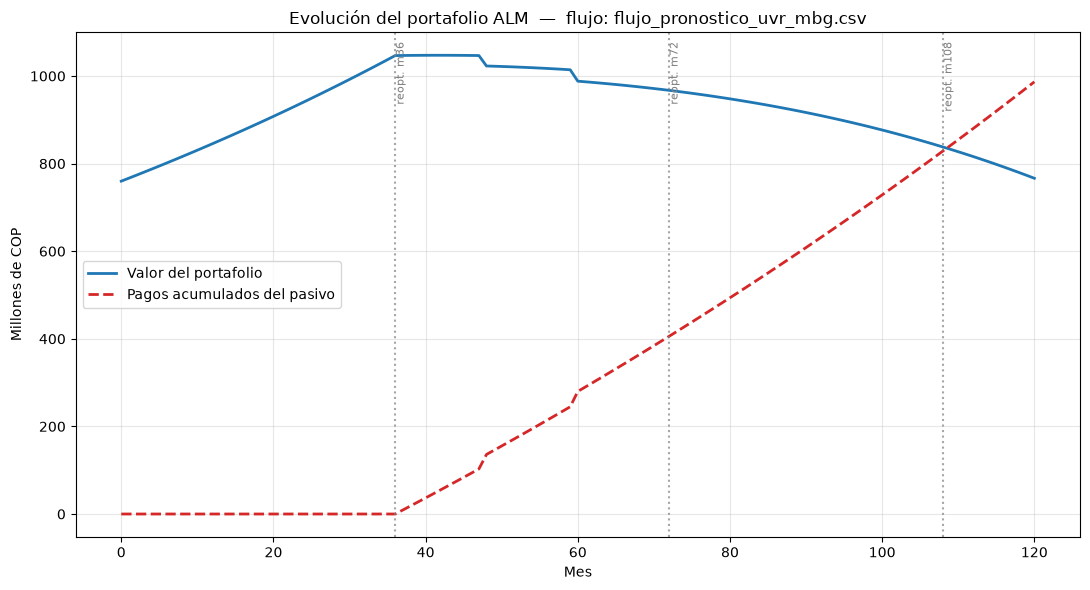

In [36]:
meses = np.arange(0, N_MESES + 1)
pago_acumulado = np.concatenate([[0.0], np.cumsum(Lt)])

fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(meses, valor_portafolio / 1e6, label='Valor del portafolio', lw=2, color='#1f77b4')
ax.plot(meses, pago_acumulado / 1e6, label='Pagos acumulados del pasivo', lw=2,
        color='#d62728', ls='--')

for _, _, mes_fin, _ in PERIODOS[:-1]:
    ax.axvline(mes_fin, color='gray', ls=':', alpha=0.7)
    ax.text(mes_fin, ax.get_ylim()[1] * 0.98, f'  reopt. m{mes_fin}',
            rotation=90, va='top', ha='left', fontsize=8, color='gray')

ax.set_xlabel('Mes')
ax.set_ylabel('Millones de COP')
ax.set_title(f'Evolución del portafolio ALM  —  flujo: {ARCHIVO_FLUJO}')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 10.4 Resumen determinista

In [37]:
residual_final = valor_portafolio[N_MESES]
total_pagado = Lt.sum()

print('=' * 55)
print('RESUMEN FINAL — ALM multiperiodo (determinista)')
print('=' * 55)
print(f'Flujo del pasivo usado    : {ARCHIVO_FLUJO}')
print(f'Capital inicial C0        : {C0:,.0f} COP')
print(f'Total pagado del pasivo   : {total_pagado:,.0f} COP')
print(f'Capital residual (mes {N_MESES}): {residual_final:,.0f} COP')
print(f'Crecimiento neto vs C0    : {residual_final / C0 - 1:+.2%}')
estado = 'SOLVENTE (nunca negativo)' if valor_portafolio[1:].min() >= 0 else 'INSOLVENTE en algun mes'
print(f'Estado de solvencia       : {estado}')
print(f'Valor mínimo del portafolio: {valor_portafolio[1:].min():,.0f} COP')

RESUMEN FINAL — ALM multiperiodo (determinista)
Flujo del pasivo usado    : flujo_pronostico_uvr_mbg.csv
Capital inicial C0        : 760,000,000 COP
Total pagado del pasivo   : 986,738,889 COP
Capital residual (mes 120): 766,568,592 COP
Crecimiento neto vs C0    : +0.86%
Estado de solvencia       : SOLVENTE (nunca negativo)
Valor mínimo del portafolio: 766,568,592 COP


## 11. Análisis de *shortfall* (Monte Carlo con las K trayectorias)

Sustituimos el retorno fijo `w'mu` por las **K trayectorias simuladas en memoria**
(`R_tray`) y medimos el riesgo de que el portafolio no alcance a cubrir el pasivo.

- **Probabilidad de shortfall**: fracción de trayectorias con `V_t < 0` en algún mes.
- **Expected Shortfall (ES)** del déficit: déficit promedio en el peor 5% de los casos.
- **Distribución del capital residual final** `V_120`.

### 11.1 Matriz de pesos por mes (sin reoptimizar en cada trayectoria)

Reutilizamos `pesos_por_periodo` de la sección 9. Los pesos solo cambian en los inicios
de periodo (meses 1, 37, 73, 109).

In [38]:
def construir_matriz_pesos_por_mes(n_meses, periodos, pesos_por_periodo, activos):
    """Devuelve W de forma (n_meses, len(activos)) con los pesos vigentes cada mes."""
    W = np.zeros((n_meses, len(activos)))
    inicios = []
    for nombre, mes_ini, mes_fin, _ in periodos:
        w = np.array([pesos_por_periodo[nombre][a] for a in activos])
        ini = mes_ini - 1
        fin = min(mes_fin, n_meses)
        if ini >= n_meses:
            continue
        W[ini:fin, :] = w
        inicios.append(mes_ini)
    return W, inicios


W_mes, inicios_periodo = construir_matriz_pesos_por_mes(
    N_SIM, PERIODOS, pesos_por_periodo, ACTIVOS_TRAY)

print(f'Inicios de periodo (cambio de pesos): meses {inicios_periodo}')
tabla_W = pd.DataFrame(
    {nombre: [pesos_por_periodo[nombre][a] for a in ACTIVOS_TRAY] for nombre, *_ in PERIODOS},
    index=ACTIVOS_TRAY,
).T
tabla_W.index.name = 'Periodo'
display(tabla_W.style.format('{:.2%}'))

Inicios de periodo (cambio de pesos): meses [1, 37, 73, 109]


,Bono,Fondo,ETF
Periodo,,,
P1,0.00%,0.00%,100.00%
P2,0.00%,0.00%,100.00%
P3,0.00%,0.00%,100.00%
P4,0.00%,0.00%,100.00%


### 11.2 Simulación de shortfall mes a mes (vectorizada)

In [39]:
def simular_shortfall(R, W, Lt, C0, n_meses, activos):
    """Simulación vectorizada de V_t = V_{t-1}(1+r_t) - L_t sobre K trayectorias."""
    K_ = R[activos[0]].shape[0]
    Rstack = np.stack([R[a] for a in activos], axis=2)   # (K, n_meses, 3)
    ret_port = np.einsum('kta,ta->kt', Rstack, W)        # (K, n_meses)

    V = np.empty((K_, n_meses + 1))
    V[:, 0] = C0
    for t in range(1, n_meses + 1):
        V[:, t] = V[:, t - 1] * (1.0 + ret_port[:, t - 1]) - Lt[t - 1]

    V_meses = V[:, 1:]
    hubo_short = (V_meses < 0).any(axis=1)
    deficit_max = np.maximum(0.0, -V_meses).max(axis=1)
    residual = V[:, n_meses]
    return {'V': V, 'hubo_short': hubo_short, 'deficit_max': deficit_max,
            'residual': residual, 'ret_port': ret_port}


sim = simular_shortfall(R_tray, W_mes, Lt[:N_SIM], C0, N_SIM, ACTIVOS_TRAY)
print(f'Simulación completada sobre {K_SIM} trayectorias y {N_SIM} meses.')
print(f'Trayectorias con shortfall: {int(sim["hubo_short"].sum())} de {K_SIM}')

Simulación completada sobre 1000 trayectorias y 120 meses.
Trayectorias con shortfall: 0 de 1000


### 11.3 Métricas de riesgo

In [40]:
def expected_shortfall_deficit(deficit_max, alpha=0.05):
    """ES del déficit: media del peor alpha de los déficits (cola superior)."""
    if deficit_max.size == 0:
        return 0.0
    k = max(1, int(np.ceil(alpha * deficit_max.size)))
    peores = np.sort(deficit_max)[::-1][:k]
    return float(peores.mean())


def resumen_residual(residual):
    return {
        'media':   float(np.mean(residual)),
        'mediana': float(np.median(residual)),
        'p5':      float(np.percentile(residual, 5)),
        'p95':     float(np.percentile(residual, 95)),
        'minimo':  float(np.min(residual)),
        'maximo':  float(np.max(residual)),
    }


ALPHA = 0.05
prob_short = float(sim['hubo_short'].mean())
es_deficit = expected_shortfall_deficit(sim['deficit_max'], alpha=ALPHA)
res_stats = resumen_residual(sim['residual'])

print('=' * 60)
print(f'MÉTRICAS DE RIESGO — flujo: {ARCHIVO_FLUJO}  |  K = {K_SIM}')
print('=' * 60)
print(f'Probabilidad de shortfall        : {prob_short:.2%}')
print(f'Expected Shortfall (deficit, {ALPHA:.0%}) : {es_deficit:,.0f} COP')
print('-' * 60)
print('Distribución del capital residual final V_120:')
for k_, v_ in res_stats.items():
    print(f'  {k_:<8}: {v_:,.0f} COP')

tabla_residual = pd.DataFrame([res_stats]).T.rename(columns={0: 'COP'})
tabla_residual.index.name = 'estadístico'
display(tabla_residual.style.format('{:,.0f}'))

MÉTRICAS DE RIESGO — flujo: flujo_pronostico_uvr_mbg.csv  |  K = 1000
Probabilidad de shortfall        : 0.00%
Expected Shortfall (deficit, 5%) : 0 COP
------------------------------------------------------------
Distribución del capital residual final V_120:
  media   : 781,584,272 COP
  mediana : 767,468,394 COP
  p5      : 494,695,783 COP
  p95     : 1,118,510,947 COP
  minimo  : 388,306,878 COP
  maximo  : 1,291,348,830 COP


,COP
estadístico,
media,"781,584,272"
mediana,"767,468,394"
p5,"494,695,783"
p95,"1,118,510,947"
minimo,"388,306,878"
maximo,"1,291,348,830"


### 11.4 Histograma del capital residual final

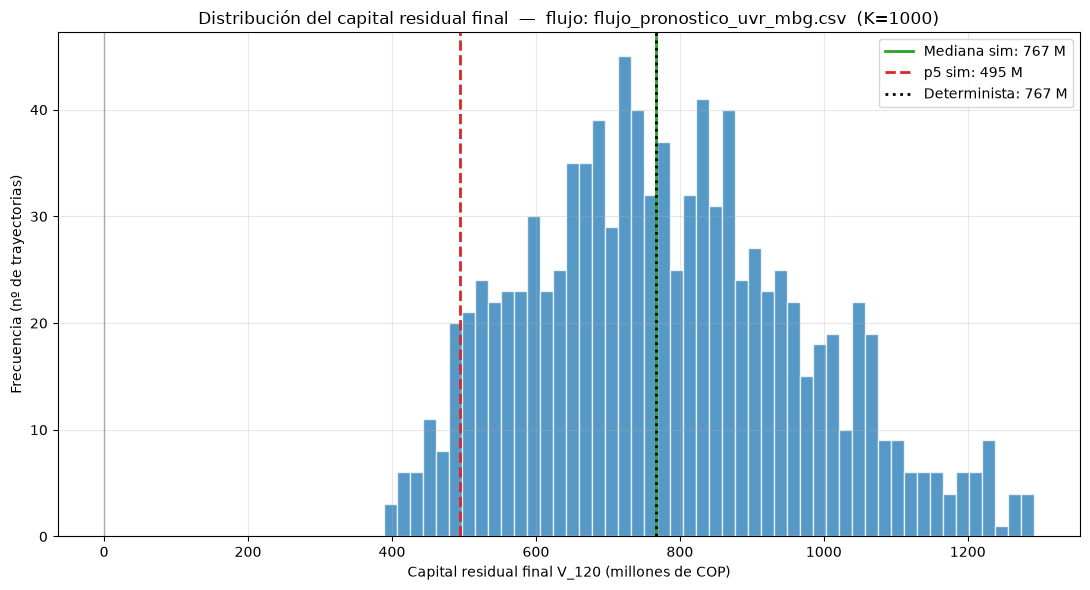

In [41]:
residual_determinista = float(valor_portafolio[N_MESES])

fig, ax = plt.subplots(figsize=(11, 6))
ax.hist(sim['residual'] / 1e6, bins=50, color='#1f77b4', alpha=0.75, edgecolor='white')
ax.axvline(res_stats['mediana'] / 1e6, color='#2ca02c', lw=2,
           label=f"Mediana sim: {res_stats['mediana']/1e6:,.0f} M")
ax.axvline(res_stats['p5'] / 1e6, color='#d62728', lw=2, ls='--',
           label=f"p5 sim: {res_stats['p5']/1e6:,.0f} M")
ax.axvline(residual_determinista / 1e6, color='black', lw=2, ls=':',
           label=f'Determinista: {residual_determinista/1e6:,.0f} M')
ax.axvline(0, color='gray', lw=1, alpha=0.6)
ax.set_xlabel('Capital residual final V_120 (millones de COP)')
ax.set_ylabel('Frecuencia (nº de trayectorias)')
ax.set_title(f'Distribución del capital residual final  —  flujo: {ARCHIVO_FLUJO}  (K={K_SIM})')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 11.5 Percentiles del valor del portafolio en el tiempo

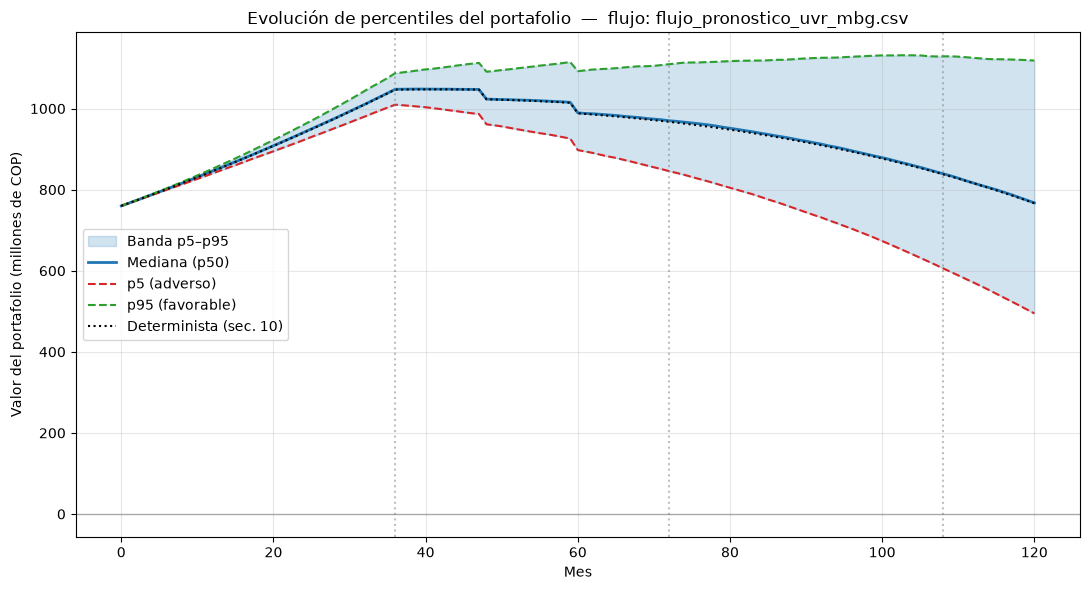

In [42]:
V = sim['V']
meses_sim = np.arange(0, N_SIM + 1)
p05 = np.percentile(V, 5,  axis=0)
p50 = np.percentile(V, 50, axis=0)
p95 = np.percentile(V, 95, axis=0)

fig, ax = plt.subplots(figsize=(11, 6))
ax.fill_between(meses_sim, p05 / 1e6, p95 / 1e6, color='#1f77b4', alpha=0.20, label='Banda p5–p95')
ax.plot(meses_sim, p50 / 1e6, color='#1f77b4', lw=2, label='Mediana (p50)')
ax.plot(meses_sim, p05 / 1e6, color='#d62728', lw=1.5, ls='--', label='p5 (adverso)')
ax.plot(meses_sim, p95 / 1e6, color='#2ca02c', lw=1.5, ls='--', label='p95 (favorable)')
ax.plot(np.arange(0, N_MESES + 1), valor_portafolio / 1e6, color='black', lw=1.5, ls=':',
        label='Determinista (sec. 10)')
ax.axhline(0, color='gray', lw=1, alpha=0.6)
for mi in inicios_periodo[1:]:
    ax.axvline(mi - 1, color='gray', ls=':', alpha=0.5)
ax.set_xlabel('Mes')
ax.set_ylabel('Valor del portafolio (millones de COP)')
ax.set_title(f'Evolución de percentiles del portafolio  —  flujo: {ARCHIVO_FLUJO}')
ax.legend(loc='best')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 11.6 Comparación: determinista vs simulado

In [43]:
comparacion = pd.DataFrame({
    'valor_COP': {
        'Residual DETERMINISTA (sec. 10)': residual_determinista,
        'Residual simulado — media':       res_stats['media'],
        'Residual simulado — mediana':     res_stats['mediana'],
        'Residual simulado — p5':          res_stats['p5'],
        'Residual simulado — p95':         res_stats['p95'],
    }
})
comparacion['vs C0'] = comparacion['valor_COP'] / C0 - 1
display(comparacion.style.format({'valor_COP': '{:,.0f}', 'vs C0': '{:+.2%}'}))

dif_med = residual_determinista - res_stats['media']
print(f'\nDeterminista - media simulada: {dif_med:,.0f} COP '
      f'({dif_med / residual_determinista:+.2%} del determinista)')
print(f'Probabilidad de shortfall: {prob_short:.2%}')
if prob_short == 0:
    print('=> Ninguna trayectoria agota el capital: plan robusto bajo este flujo.')
else:
    print('=> Hay trayectorias que agotan el capital: revisar riesgo/pesos/flujo.')

,valor_COP,vs C0
Residual DETERMINISTA (sec. 10),"766,568,592",+0.86%
Residual simulado — media,"781,584,272",+2.84%
Residual simulado — mediana,"767,468,394",+0.98%
Residual simulado — p5,"494,695,783",-34.91%
Residual simulado — p95,"1,118,510,947",+47.17%



Determinista - media simulada: -15,015,681 COP (-1.96% del determinista)
Probabilidad de shortfall: 0.00%
=> Ninguna trayectoria agota el capital: plan robusto bajo este flujo.


## 12. Comparación de los tres pronósticos del pasivo (MBG / ARIMA / SARIMAX)

Mismas trayectorias y mismos pesos óptimos; solo cambia la serie `L_t`. Así se ve qué
pronóstico del pasivo es más exigente para el plan de inversión.

In [44]:
def shortfall_por_flujo(archivos, R, W, C0, n_meses, activos, alpha=0.05):
    """Corre la simulación de shortfall para varios flujos del pasivo."""
    filas = []
    for arch in archivos:
        ruta = os.path.join(CARPETA_FLUJOS, arch)
        if not os.path.exists(ruta):
            print(f'  [aviso] no existe el flujo {arch}; se omite.')
            continue
        L = pd.read_csv(ruta).sort_values('periodo')['Lt'].to_numpy()
        if len(L) < n_meses:
            print(f'  [aviso] {arch} tiene {len(L)} meses (<{n_meses}); se omite.')
            continue
        s = simular_shortfall(R, W, L[:n_meses], C0, n_meses, activos)
        rs = resumen_residual(s['residual'])
        filas.append({
            'flujo': arch,
            'prob_shortfall': float(s['hubo_short'].mean()),
            'ES_deficit_5pct': expected_shortfall_deficit(s['deficit_max'], alpha),
            'residual_media': rs['media'],
            'residual_mediana': rs['mediana'],
            'residual_p5': rs['p5'],
            'residual_p95': rs['p95'],
        })
    return pd.DataFrame(filas).set_index('flujo') if filas else pd.DataFrame()


comp_short = shortfall_por_flujo(
    ['flujo_pronostico_uvr_mbg.csv',
     'flujo_pronostico_uvr_arima.csv',
     'flujo_pronostico_uvr_Sarimax.csv'],
    R_tray, W_mes, C0, N_SIM, ACTIVOS_TRAY, alpha=0.05,
)
if not comp_short.empty:
    display(comp_short.style.format({
        'prob_shortfall': '{:.2%}',
        'ES_deficit_5pct': '{:,.0f}',
        'residual_media': '{:,.0f}',
        'residual_mediana': '{:,.0f}',
        'residual_p5': '{:,.0f}',
        'residual_p95': '{:,.0f}',
    }))

,prob_shortfall,ES_deficit_5pct,residual_media,residual_mediana,residual_p5,residual_p95
flujo,,,,,,
flujo_pronostico_uvr_mbg.csv,0.00%,0,"781,584,272","767,468,394","494,695,783","1,118,510,947"
flujo_pronostico_uvr_arima.csv,0.00%,0,"941,223,053","926,677,226","641,574,685","1,289,114,231"
flujo_pronostico_uvr_Sarimax.csv,0.00%,0,"861,711,307","848,561,355","568,882,031","1,203,746,521"


## 13. (Opcional) Exportar resultados a disco

Por defecto **desactivado** (`EXPORTAR = False`). Si lo activas, escribe los mismos
archivos que generaban los notebooks originales (`mu_activos.csv`, `Sigma_*.csv`,
`trayectorias_mensuales*.csv/.npz`) por si los necesitas fuera de este notebook.

In [45]:
EXPORTAR = False
DIR_RESULTS = '../pronosticosActivos'

if EXPORTAR:
    os.makedirs(DIR_RESULTS, exist_ok=True)

    # mu y Sigma
    pd.DataFrame({'Activo': ACTIVOS, 'mu_mensual': mu_vec, 'mu_anual': mu_annual}).to_csv(
        os.path.join(DIR_RESULTS, 'mu_activos.csv'), index=False)
    Sigma_df.to_csv(os.path.join(DIR_RESULTS, 'Sigma_mensual.csv'))
    pd.DataFrame(Sigma_annual, index=ACTIVOS, columns=ACTIVOS).to_csv(
        os.path.join(DIR_RESULTS, 'Sigma_anual.csv'))

    # Trayectorias mensuales (120 meses) por activo + npz
    month_cols = [f'mes_{m+1}' for m in range(N_MONTHS_EXPORT)]
    for asset in assets:
        pd.DataFrame(R_tray[asset], columns=month_cols).to_csv(
            os.path.join(DIR_RESULTS, f'trayectorias_mensuales_{asset}.csv'), index=False)
    np.savez_compressed(
        os.path.join(DIR_RESULTS, 'trayectorias_mensuales.npz'),
        Bono=R_tray['Bono'], Fondo=R_tray['Fondo'], ETF=R_tray['ETF'])

    print(f'Exportado en: {os.path.abspath(DIR_RESULTS)}')
else:
    print('Exportación desactivada (EXPORTAR = False). Todo queda en memoria.')

Exportación desactivada (EXPORTAR = False). Todo queda en memoria.
